# Exploratory data analysis

Exploration and figures for the report. All cleaning logic lives in `preprocessing.py`
so that `run.py` uses exactly the same transformations; this notebook only imports it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from preprocessing import load_data, clean_raw, Preprocessor

x_train, x_test, y_train, train_ids, test_ids, columns = load_data("dataset")
y = (y_train == 1).astype(int)
print("train", x_train.shape, "test", x_test.shape)
print(f"positives: {y.sum()} / {len(y)} = {y.mean():.2%}")

train (328135, 321) test (109379, 321)
positives: 28975 / 328135 = 8.83%


## Class imbalance
Only ~9% of respondents have MICHD. Predicting always "no" gives ~91% accuracy and F1 = 0,
so we evaluate with F1 and tune the decision threshold.

## Missing values per column

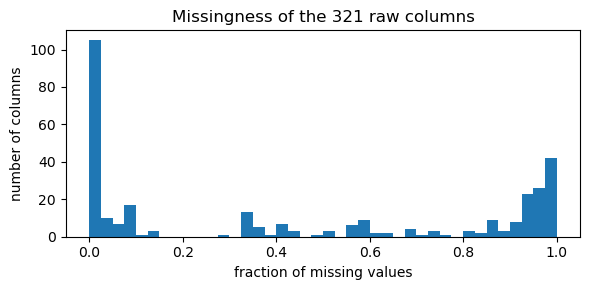

columns >50% missing: 147  >80%: 116


In [2]:
nan_frac = np.isnan(x_train).mean(axis=0)
plt.figure(figsize=(6, 3))
plt.hist(nan_frac, bins=40)
plt.xlabel("fraction of missing values"); plt.ylabel("number of columns")
plt.title("Missingness of the 321 raw columns")
plt.tight_layout(); plt.show()
print("columns >50% missing:", (nan_frac > 0.5).sum(), " >80%:", (nan_frac > 0.8).sum())

Missingness is bimodal: core questions are almost always answered, while optional modules
and follow-up questions (only asked after certain answers) are mostly empty.

## BRFSS special codes
Answers such as 77/99 ("don't know"/"refused") and 88 ("none") are stored as numbers.
Left as-is, a model would read 88 bad-health days as more than 30.

In [3]:
j = columns.index("PHYSHLTH")
vals, counts = np.unique(x_train[:, j], return_counts=True)
print("PHYSHLTH raw values (top):", dict(zip(vals[-5:], counts[-5:])))

x_clean, clean_cols = clean_raw(np.vstack([x_train, x_test]), columns)
x_clean = x_clean[:len(y)]
jc = clean_cols.index("PHYSHLTH")
v = x_clean[:, jc]
print("after clean_raw: min", np.nanmin(v), "max", np.nanmax(v), "missing", np.isnan(v).mean().round(4))
print("columns kept after dropping admin / encoded columns:", len(clean_cols))

PHYSHLTH raw values (top): {30.0: 25233, 77.0: 5587, 88.0: 204264, 99.0: 1520, nan: 1}


after clean_raw: min 0.0 max 30.0 missing 0.0217
columns kept after dropping admin / encoded columns: 269


## Positive rate by a few key features

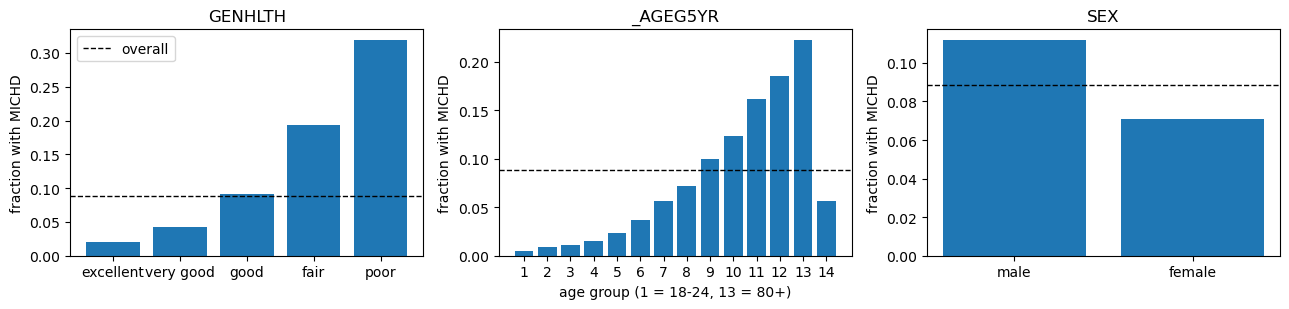

In [4]:
def positive_rate_by(name, ax, labels=None):
    v = x_clean[:, clean_cols.index(name)]
    levels = np.unique(v[~np.isnan(v)])
    rates = [y[v == lv].mean() for lv in levels]
    ax.bar([labels[int(lv)] if labels else f"{lv:g}" for lv in levels], rates)
    ax.axhline(y.mean(), color="k", ls="--", lw=1, label="overall")
    ax.set_title(name); ax.set_ylabel("fraction with MICHD")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
positive_rate_by("GENHLTH", axes[0], {1: "excellent", 2: "very good", 3: "good", 4: "fair", 5: "poor"})
positive_rate_by("_AGEG5YR", axes[1])
positive_rate_by("SEX", axes[2], {1: "male", 2: "female"})
axes[1].set_xlabel("age group (1 = 18-24, 13 = 80+)")
axes[0].legend(); plt.tight_layout(); plt.show()

Self-rated general health and age are strongly associated with MICHD:
the risk grows almost monotonically with age group and worse general health.

## Features after preprocessing

design matrix: (328135, 443)
categorical columns: 110  continuous: 47  missingness indicators: 114


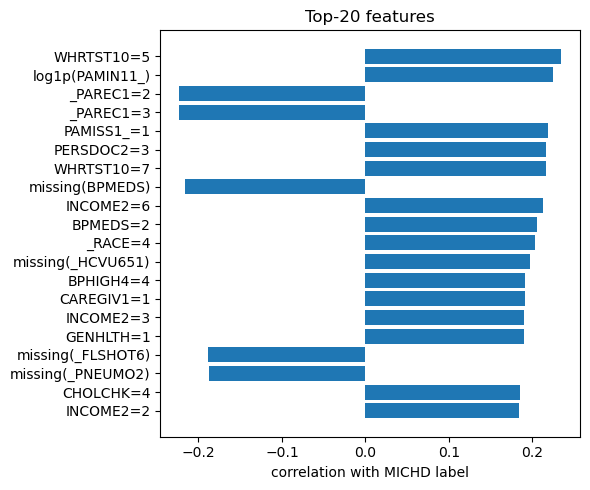

In [5]:
prep = Preprocessor(max_nan_frac=0.8).fit(x_clean, clean_cols)
X = prep.transform(x_clean)
print("design matrix:", X.shape)
print("categorical columns:", len(prep.categorical), " continuous:", len(prep.continuous),
      " missingness indicators:", len(prep.indicator_cols))

# Correlation of each feature with the label (point-biserial).
Xc = X[:, 1:] - X[:, 1:].mean(0)
yc = y - y.mean()
corr = (Xc.T @ yc) / (np.sqrt((Xc ** 2).sum(0)) * np.sqrt((yc ** 2).sum()) + 1e-12)
top = np.argsort(-np.abs(corr))[:20]
names = np.array(prep.feature_names[1:])
plt.figure(figsize=(6, 5))
plt.barh(names[top][::-1], corr[top][::-1])
plt.xlabel("correlation with MICHD label"); plt.title("Top-20 features")
plt.tight_layout(); plt.show()